In [33]:
import os
import json
import pickle
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn

from pathlib import Path
from lazy_datasets import VisiumSpotDataset
from lazy_datasets import get_dataset_dimensions, compute_gene_statistics

In [42]:
@torch.no_grad()
def plot_gene_spatial_prediction(
    model,
    dataset,
    array_id,
    gene,
    gene_mean,
    gene_std,
    target_genes,
    device,
    batch_size=1024,
    cmap="viridis",
    spot_size=8,
    show_residual=False,
    invert_log=True,
    percentile_clip=None,
):
    """
    Plot observed and model-predicted expression for one gene
    across one Visium array.

    Parameters
    ----------
    model : torch.nn.Module
        Trained expression prediction model.

    dataset : VisiumSpotDataset
        Dataset containing the requested array. Must have
        return_coords=True.

    array_id : str
        Array to plot.

    gene : str or int
        Gene name or gene index.

    gene_mean, gene_std : torch.Tensor
        Training-set normalization statistics [n_genes].

    target_genes : sequence
        Ordered gene names corresponding to model outputs.

    device : torch.device
        Device on which to run inference.

    batch_size : int
        Inference batch size.

    cmap : str
        Matplotlib colormap.

    spot_size : float
        Scatter point size.

    show_residual : bool
        If True, add predicted - observed as a third panel.

    invert_log : bool
        If True, convert log1p-normalized expression back to
        normalized-expression units using expm1.

    percentile_clip : float or None
        Optional upper percentile for visualization scaling.
        For example, 99 will set vmax to the joint 99th percentile
        of observed and predicted values.

    Returns
    -------
    fig, axes
    """

    # ------------------------------------------------------
    # Resolve gene
    # ------------------------------------------------------

    target_genes = list(target_genes)

    if isinstance(gene, str):
        if gene not in target_genes:
            raise ValueError(
                f"{gene!r} is not among the target genes."
            )
        gene_idx = target_genes.index(gene)
        gene_name = gene

    else:
        gene_idx = int(gene)

        if not 0 <= gene_idx < len(target_genes):
            raise IndexError(
                f"gene index {gene_idx} outside "
                f"[0, {len(target_genes)})"
            )

        gene_name = target_genes[gene_idx]

    # ------------------------------------------------------
    # Find requested array
    # ------------------------------------------------------

    matches = [
        i for i, info in enumerate(dataset.arrays)
        if str(info["array_id"]) == str(array_id)
    ]

    if len(matches) != 1:
        raise ValueError(
            f"Expected exactly one array matching {array_id!r}; "
            f"found {len(matches)}."
        )

    array_idx = matches[0]

    start = (
        0
        if array_idx == 0
        else int(dataset.cumulative_sizes[array_idx - 1])
    )

    stop = int(dataset.cumulative_sizes[array_idx])

    # ------------------------------------------------------
    # Run inference
    # ------------------------------------------------------

    model.eval()
    model.to(device)

    mu = gene_mean[gene_idx].to(device)
    sigma = gene_std[gene_idx].to(device)

    observed = []
    predicted = []
    coordinates = []

    for batch_start in range(start, stop, batch_size):

        batch_stop = min(
            batch_start + batch_size,
            stop,
        )

        # Since this is visualization rather than training,
        # directly retrieving this small block is sufficient.
        items = [
            dataset[i]
            for i in range(batch_start, batch_stop)
        ]

        x = torch.stack([
            item["image"] for item in items
        ]).to(device)

        y = torch.stack([
            item["expression"] for item in items
        ])

        coords = torch.stack([
            item["coords"] for item in items
        ])

        pred_standardized = model(x)[:, gene_idx]

        # Model predicts standardized log-expression.
        pred_log = (
            pred_standardized * sigma + mu
        )

        # Dataset expression is assumed to contain the
        # unstandardized log-expression target.
        obs_log = y[:, gene_idx].to(device)

        if invert_log:
            pred_value = torch.expm1(pred_log)
            obs_value = torch.expm1(obs_log)

            # Numerical/model predictions can become slightly
            # negative after inversion.
            pred_value = pred_value.clamp_min(0)

        else:
            pred_value = pred_log
            obs_value = obs_log

        predicted.append(
            pred_value.cpu().numpy()
        )

        observed.append(
            obs_value.cpu().numpy()
        )

        coordinates.append(
            coords.numpy()
        )

    predicted = np.concatenate(predicted)
    observed = np.concatenate(observed)
    coordinates = np.concatenate(coordinates)

    # ------------------------------------------------------
    # Common expression scale
    # ------------------------------------------------------

    joint_values = np.concatenate([
        observed,
        predicted,
    ])

    vmin = np.nanmin(joint_values)

    if percentile_clip is None:
        vmax = np.nanmax(joint_values)
    else:
        vmax = np.nanpercentile(
            joint_values,
            percentile_clip,
        )

    # ------------------------------------------------------
    # Plot
    # ------------------------------------------------------
    
    n_panels = 3 if show_residual else 2
    
    fig, axes = plt.subplots(
        1,
        n_panels,
        figsize=(6 * n_panels, 6),
        constrained_layout=True,
    )
    
    x_coord = coordinates[:, 0]
    y_coord = coordinates[:, 1]
    
    sc_obs = axes[0].scatter(
        x_coord,
        y_coord,
        c=observed,
        s=spot_size,
        cmap=cmap,
        vmin=vmin,
        vmax=vmax,
    )
    
    axes[0].set_title(
        f"{gene_name}: observed"
    )
    
    sc_pred = axes[1].scatter(
        x_coord,
        y_coord,
        c=predicted,
        s=spot_size,
        cmap=cmap,
        vmin=vmin,
        vmax=vmax,
    )
    
    axes[1].set_title(
        f"{gene_name}: predicted"
    )
    
    for ax in axes[:2]:
        ax.invert_yaxis()
        ax.set_aspect("equal")
        ax.set_xlabel("x")
        ax.set_ylabel("y")
    
    label = (
        "Normalized expression"
        if invert_log
        else "log1p normalized expression"
    )
    
    # Shared colorbar for observed + predicted.
    # constrained_layout will allocate space for it properly.
    fig.colorbar(
        sc_pred,
        ax=axes[:2],
        label=label,
        shrink=0.8,
        pad=0.02,
    )
    
    # ------------------------------------------------------
    # Optional residual map
    # ------------------------------------------------------
    
    if show_residual:
    
        residual = predicted - observed
    
        residual_max = np.nanmax(
            np.abs(residual)
        )
    
        sc_res = axes[2].scatter(
            x_coord,
            y_coord,
            c=residual,
            s=spot_size,
            cmap="coolwarm",
            vmin=-residual_max,
            vmax=residual_max,
        )
    
        axes[2].invert_yaxis()
        axes[2].set_aspect("equal")
        axes[2].set_xlabel("x")
        axes[2].set_ylabel("y")
    
        axes[2].set_title(
            f"{gene_name}: predicted − observed"
        )
    
        fig.colorbar(
            sc_res,
            ax=axes[2],
            label="Prediction residual",
            shrink=0.8,
            pad=0.02,
        )
    
    fig.suptitle(
        f"Array {array_id}",
        fontsize=14,
    )
    
    return fig, axes

### Load data and splits

In [3]:
data_dir = Path('/commons/groups/phatnani_lab/adaly/BERST_data')
root_dir = data_dir / 'processed'
split = pickle.load(open(root_dir / 'TVTSPLIT_20260922.pickle', 'rb'))

train = split['train']
val = split['val']
test = split['test']

print(len(train), 'training arrays')
print(len(val), 'validation arrays')
print(len(test), 'test arrays')

assert len(np.intersect1d(train, val)) == 0
assert len(np.intersect1d(train, test)) == 0

741 training arrays
159 validation arrays
159 test arrays


In [29]:
train_dataset = VisiumSpotDataset(root_dir, array_ids=train, return_coords=True)
val_dataset = VisiumSpotDataset(root_dir, array_ids=val, return_coords=True)
test_dataset = VisiumSpotDataset(root_dir, array_ids=test, return_coords=True)

In [12]:
# Determine input and output dimensions
input_dim, n_genes = get_dataset_dimensions(
    train_dataset
)

# Calculate input scaling parameters from train fold
gene_mean, gene_std = compute_gene_statistics(
    train_dataset
)

print(f"Image feature dimension: {input_dim}")
print(f"Number of target genes: {n_genes}")

Image feature dimension: 2560
Number of target genes: 211


### Spotwise models

In [8]:
DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)
print(f"Using device: {DEVICE}")

Using device: cpu


In [7]:
class MLPExpressionModel(nn.Module):
    """
    Configurable MLP for predicting gene expression
    from pretrained image features.

    Architecture:
        Input (input_dim)
            |
        [Linear -> LayerNorm -> GELU -> Dropout]
            |             repeated n_blocks times
            |
        Linear -> latent_dim
            |
        Expression head -> n_genes

    Parameters
    ----------
    input_dim : int
        Number of input image features.

    n_genes : int
        Number of target genes.

    n_blocks : int
        Number of hidden blocks controlling model complexity.

    hidden_dim : int
        Width of each hidden block.

    latent_dim : int
        Dimension of the final image representation.

    dropout : float
        Dropout probability.
    """

    def __init__(
        self,
        input_dim,
        n_genes,
        n_blocks=2,
        hidden_dim=1024,
        latent_dim=256,
        dropout=0.2,
    ):
        super().__init__()

        if n_blocks < 0:
            raise ValueError("n_blocks must be nonnegative")

        layers = [
            nn.LayerNorm(input_dim)
        ]

        current_dim = input_dim

        # -----------------------------------------
        # Hidden blocks
        # -----------------------------------------

        for _ in range(n_blocks):

            layers.extend([
                nn.Linear(
                    current_dim,
                    hidden_dim,
                ),
                nn.LayerNorm(hidden_dim),
                nn.GELU(),
                nn.Dropout(dropout),
            ])

            current_dim = hidden_dim

        # -----------------------------------------
        # Final latent projection
        # -----------------------------------------

        layers.append(
            nn.Linear(
                current_dim,
                latent_dim,
            )
        )

        layers.append(nn.GELU())

        self.encoder = nn.Sequential(*layers)

        # -----------------------------------------
        # Gene expression prediction
        # -----------------------------------------

        self.expression_head = nn.Linear(
            latent_dim,
            n_genes,
        )

    def forward(self, x):

        z = self.encoder(x)

        return self.expression_head(z)

In [18]:
# Initialize models 
models = {}

for b in range(5): 
    mlp_model = MLPExpressionModel(
        input_dim=input_dim,
        n_genes=n_genes,
        n_blocks=b,
        hidden_dim=1024,
        latent_dim=256,
        dropout=0.2,
    )

    param_file = 'results/spotwise_mlp/baseline1_mlp_b%d.pt' % b

    checkpoint = torch.load(
        param_file,
        map_location=DEVICE,
    )

    mlp_model.load_state_dict(
        checkpoint["model_state_dict"]
    )

    mlp_model = mlp_model.to(DEVICE)
    mlp_model.eval()

    models[b] = mlp_model

### Plot on tissues

In [44]:
plot_genes = {
    'SNAP25': 'ENSG00000132639',
    'MOBP': 'ENSG00000168314',
    'MBP': 'ENSG00000197971',
    'AIF1': 'ENSG00000237727',
    'PCP4': 'ENSG00000183036'
}

plot_array = test[0]
plot_array

np.str_('CU114-U54-HRA-102-D')

In [27]:
# Load gene names
data_dir = '/commons/groups/phatnani_lab/adaly/BERST_data/processed'
adir = os.path.join(data_dir, plot_array)
        
metafile = os.path.join(adir, 'metadata.json')
meta = json.loads(open(metafile).read())

target_genes = meta['target_genes']

In [39]:
df_map = pd.read_csv('/commons/groups/phatnani_lab/adaly/BERST_data/CNS_ENSEMBL_to_gene_symbol.csv',
                    header=0, index_col=0)
target_genes = df_map.loc[target_genes, 'gene_symbol']

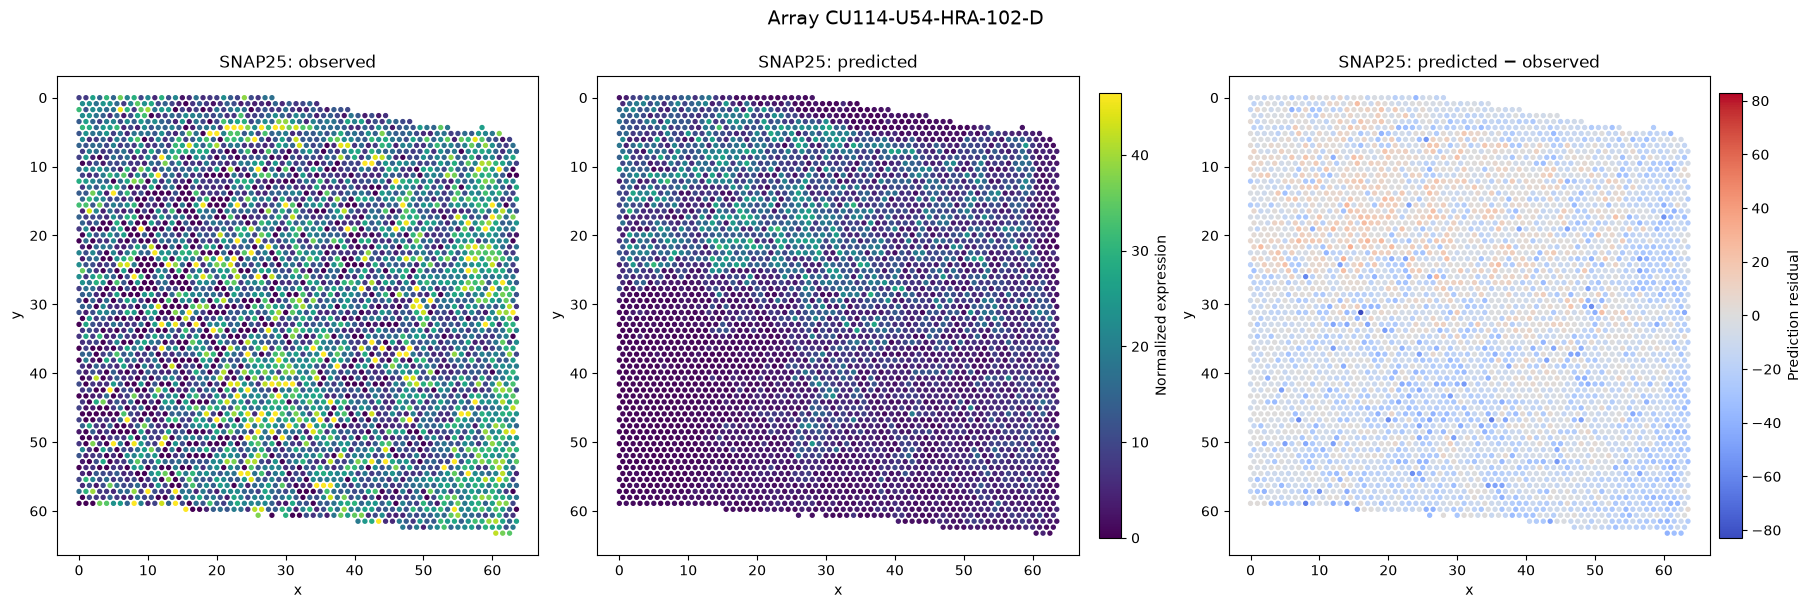

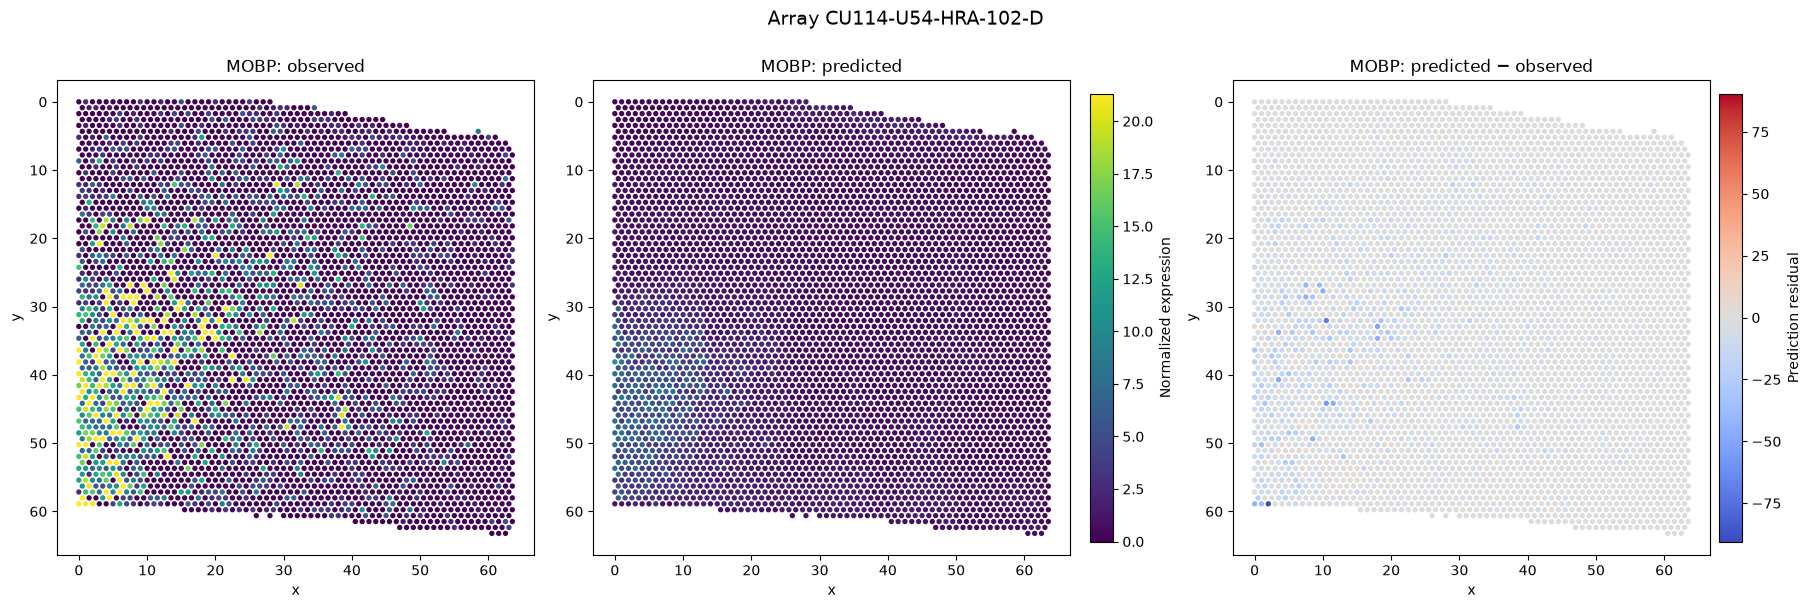

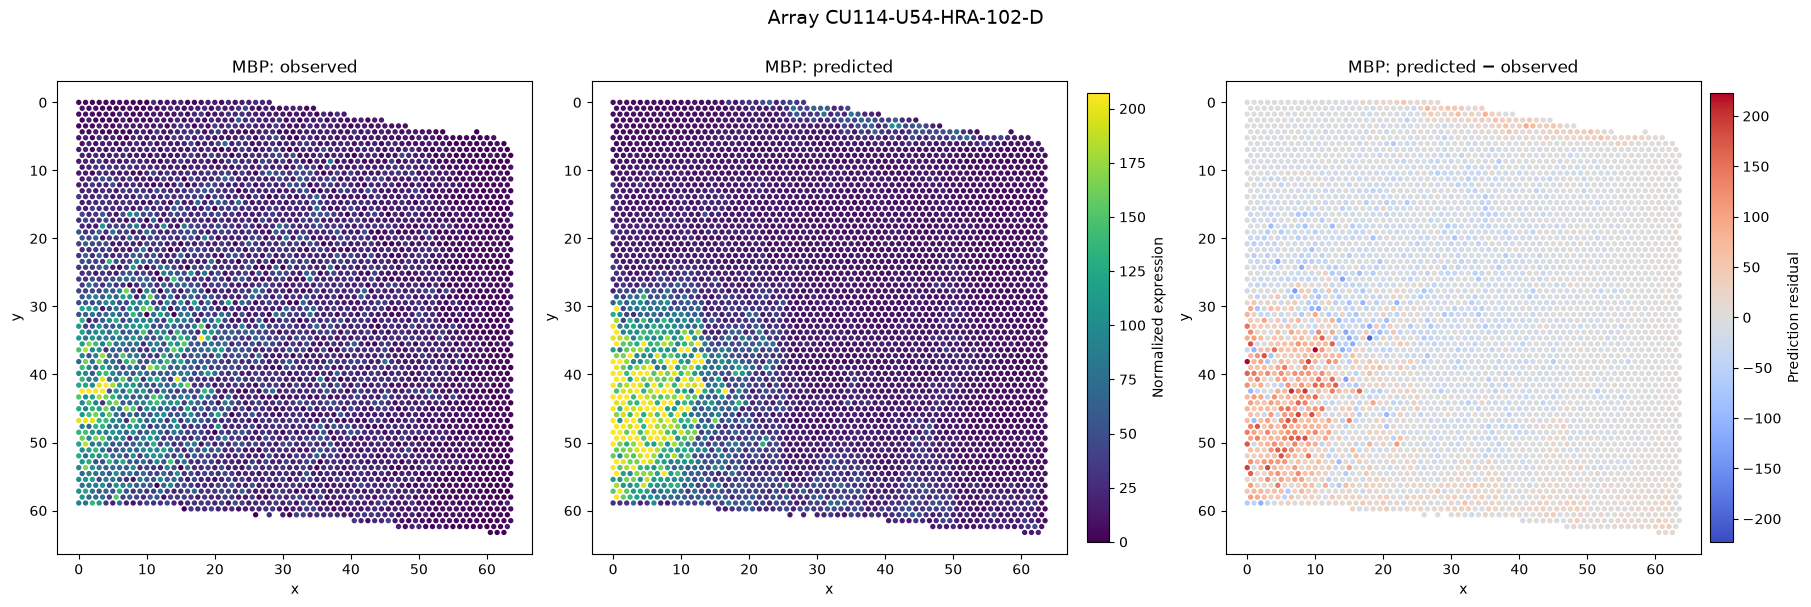

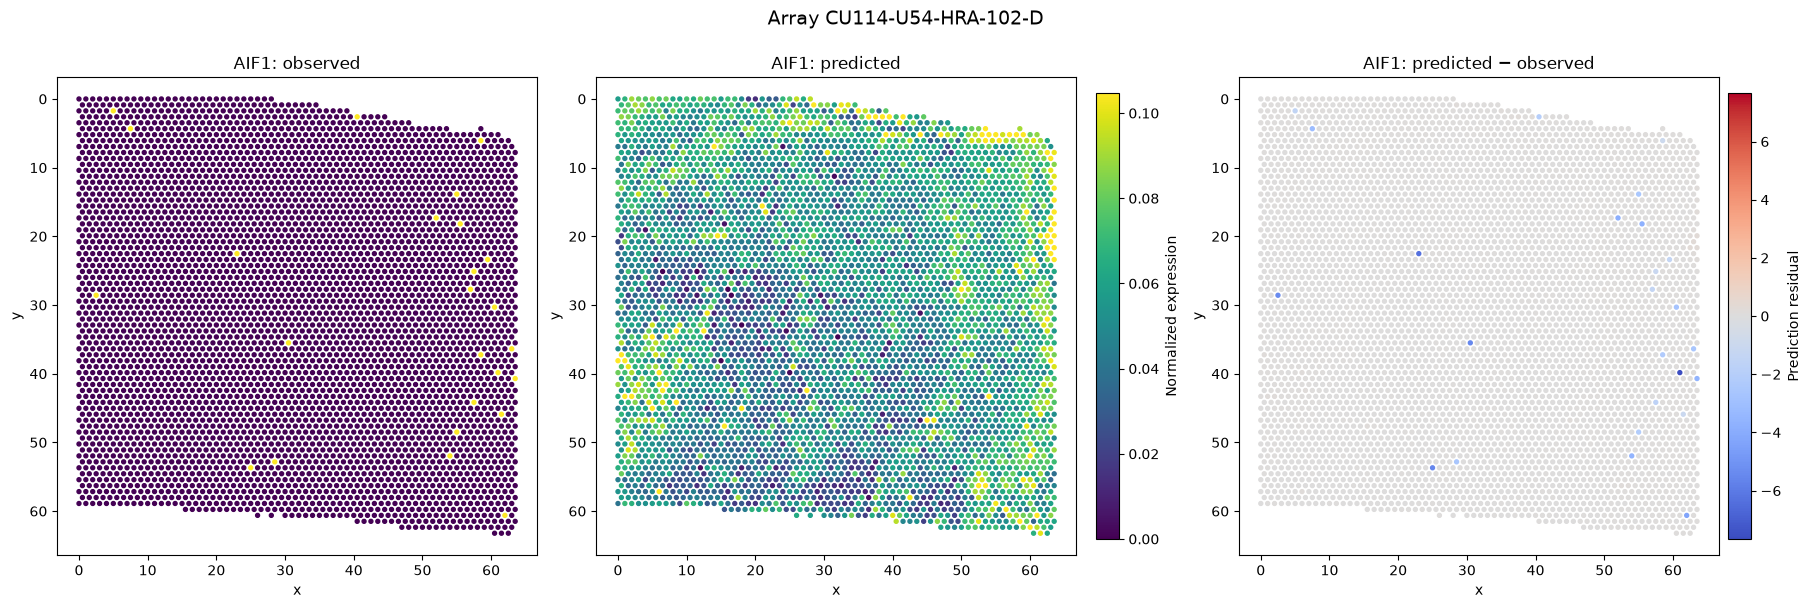

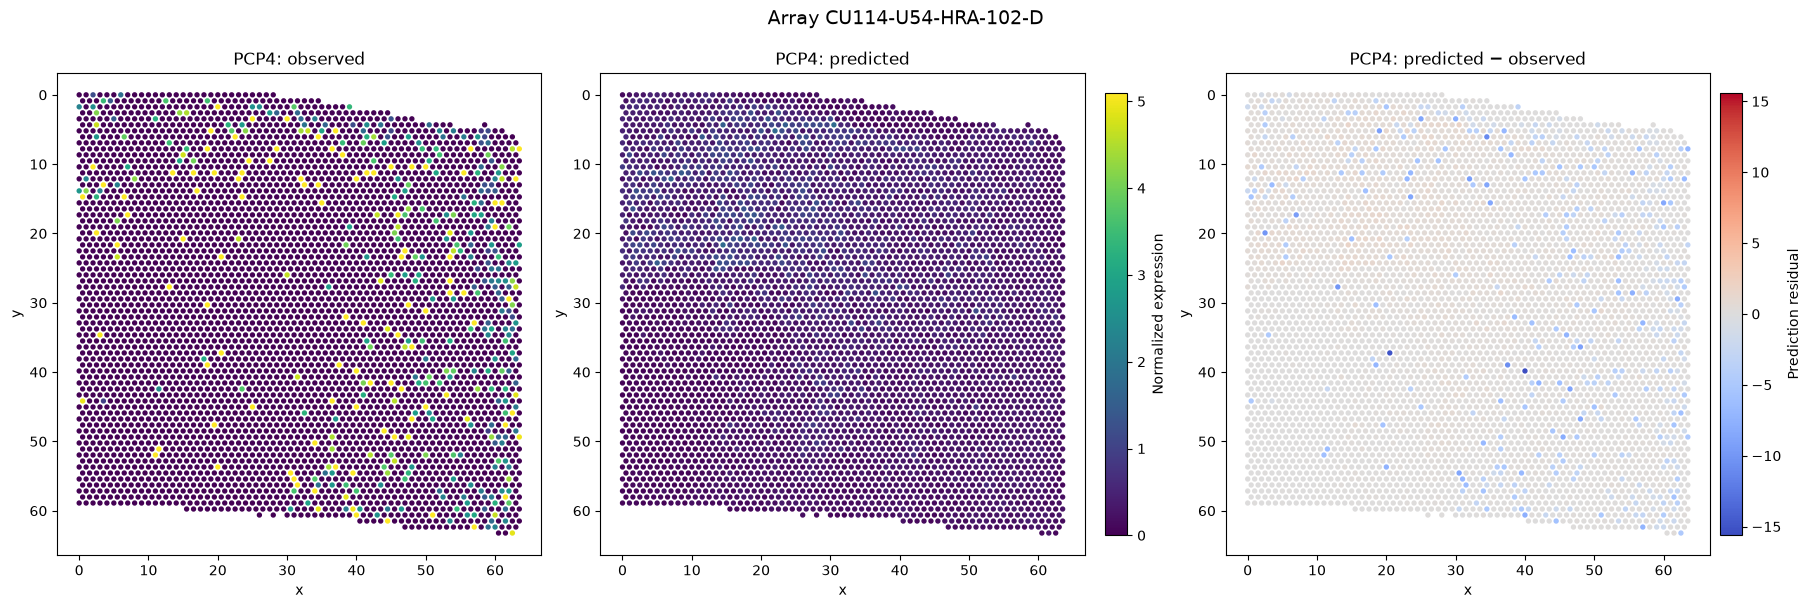

In [45]:
for common, ens in plot_genes.items():
    fig, ax = plot_gene_spatial_prediction(
        model=models[3],
        dataset=test_dataset,
        array_id=plot_array,
        gene=common,
        gene_mean=gene_mean,
        gene_std=gene_std,
        target_genes=target_genes,
        device=DEVICE,
        show_residual=True,
        percentile_clip=99,
    )